<a href="https://colab.research.google.com/github/SNIGDHA-ms24043/IDC-PROJECT--Music-Genre-Classification/blob/main/Music_Genre_IDC_Project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
print("let's goooo")
print("music genre classification ")
print("features ")

let's goooo
music genre classification 
features 


In [ ]:
# Snigdha
'''
Roadmap
1) create table => Use audio features such as MFCC,chroma, spectral centroid, tempo and energy.=> done already
2) Start with extracted-feature CSV if audio processing is too hard.
Advanced one can use Librosa to extract features from .wav files. => Librosa is a Python library specifically designed for analyzing audio and music.
.wav is an audio file format.
3)EDA: compare tempo, spectral features and MFCC patterns across genres=> done
4)Classification: KNN, SVM, RandomForest, Logistic Regression.Feature scaling is important for KNN/SVM.Optional deep learning: CNN on spectrogram images.
5)Model comparison and confusion matrix.
Short audio/AI reflection: which genres are confused and why?
6)Metrics: accuracy, macro F1, confusion matrix.
Check class balance across genres.
Extension: build a simple song-similarity recommender using
cosine similarity.

In [ ]:
# Snigdha
'''importing files and show number of columns and rows
'''
import pandas as pd
df=pd.read_excel("/content/features_3_sec.csv.xlsx")
#f-string (formatted string).=>It allows you to put Python variables/calculations directly inside a piece of text using {}
print(f"Loaded rows={df.shape[0]}, columns={df.shape[1]}")

Loaded rows=998, columns=60


In [ ]:
# Snigdha
'''
Data description
1) filename= the genre of a music
2) length = duration of the song (seconds)
3) chroma_stft=Average chroma feature calculated using STFT *
4) rms=Root Mean Square energy *
5) spectral_centroid=Center of the frequency spectrum ["center of mass" of the frequencies]
6) spectral_bandwidth=Spread of frequencies around the spectral centroid
7) rolloff=Frequency below which a chosen percentage of total spectral energy lies
8) zero_crossing_rate=Rate at which the waveform crosses zero
9) harmony=Harmonic component of the audio
10)perceptr=Perceptual/tonal audio feature in this dataset *
11)tempo=Estimated tempo=> estimated speed of the music, generally expressed in BPM: beats per minute.
12)mfcc [1-20]=20 Mel-Frequency Cepstral Coefficients=> they provide information about the spectral shape/timbre of sound, using a frequency representation related to human auditory perception.
[compact numerical description of characteristics of the sound's spectrum]
13)label=Genre/class assigned to the song

Notes

3)Chroma looks at the distribution of musical pitch classes.
STFT = Short-Time Fourier Transform.
It allows us to examine the frequency content of the music over short periods of time.
chroma_stft tells us about the distribution of musical pitch/harmonic content over time.

4) as a measure related to the energy/intensity of the audio signal.

10)The name perceptr isn't one of the standard Librosa feature names in the same straightforward way as tempo, rms, spectral_centroid, or mfcc.
It may represent a perceptual/tonal feature calculated by the dataset's feature-extraction pipeline.

In [ ]:
#gurleen
# EDA Notebook with genre comparison plots(minimum deliverables)

# combined dataframe
all_sheets = pd.read_excel("/content/features_3_sec.csv.xlsx", sheet_name=None)
#sheet_name=None: Tells Pandas to read every single worksheet tab in the Excel file, instead of stopping after the first tab.
'''Output: Creates a Python dictionary where:
Keys = Tab names (e.g., 'CLASSICAL', 'ROCK', 'POP').
Values = Individual DataFrames containing the rows for that specific genre tab.'''

df = pd.concat(all_sheets.values(), ignore_index=True)
#Vertical Stacking:Because every sheet has the same column headers,Pandas stacks the sheets vertically on top of each other.
#with ignore_index=True, you ensure both label indexing (.loc) and positional indexing (.iloc) behave predictably.(assigns clean Index 0 to 5992)
print(f"Combined DataFrame shape: {df.shape}")

print("\nSong / Slice counts per genre:")
print(df["label"].value_counts())


Combined DataFrame shape: (5993, 60)

Song / Slice counts per genre:
label
pop          1000
jazz         1000
disco         999
classical     998
rock          998
hiphop        998
Name: count, dtype: int64


In [ ]:
#gurleen
#data quality check
display(df.describe())
print("dtypes")
display(df.dtypes)
print("isna")
display(df.isna().sum())

,l,chroma_stft_mean,chroma_stft_var,rms_mean,rms_var,spectral_centroid_mean,spectral_centroid_var,spectral_bandwidth_mean,spectral_bandwidth_var,rolloff_mean,...,mfcc16_var,mfcc17_mean,mfcc17_var,mfcc18_mean,mfcc18_var,mfcc19_mean,mfcc19_var,mfcc20_mean,mfcc20_var,length
count,998.0,5993.000000,5993.000000,5993.000000,5.993000e+03,5993.000000,5.993000e+03,5993.000000,5.993000e+03,5993.000000,...,5993.000000,5993.000000,5993.000000,5993.000000,5993.000000,5993.000000,5993.000000,5993.000000,5993.000000,4995.0
mean,66149.0,0.369765,0.085313,0.128493,3.138759e-03,2265.230236,4.501238e+05,2305.666850,1.157067e+05,4729.658658,...,51.496599,-2.745784,53.746498,0.696740,55.751498,-1.806700,59.343750,-0.640064,62.662091,66149.0
std,0.0,0.092304,0.008304,0.074561,4.253689e-03,800.434954,4.692345e+05,612.913004,1.023451e+05,1809.642137,...,38.789302,5.686764,39.518274,5.231412,41.809001,5.266784,47.382750,5.293887,52.241778,0.0
min,66149.0,0.107108,0.038064,0.000953,4.379535e-08,472.741636,8.118813e+02,499.162910,1.653263e+03,658.336276,...,3.070262,-27.809795,1.624544,-20.733809,3.437439,-27.448456,3.065302,-35.640659,1.429122,66149.0
25%,66149.0,0.299573,0.080289,0.069345,5.016397e-04,1643.004276,1.150352e+05,1863.473852,4.868666e+04,3330.772423,...,29.183075,-6.429787,29.949141,-2.635681,30.325510,-5.174462,31.134136,-3.789416,31.285770,66149.0
50%,66149.0,0.381032,0.084971,0.121310,1.574680e-03,2282.579370,2.931697e+05,2311.503052,8.873703e+04,4803.974797,...,41.604786,-2.846961,43.233727,0.431402,43.638138,-2.048507,45.675880,-0.895388,47.818382,66149.0
75%,66149.0,0.439004,0.090665,0.182003,3.873321e-03,2829.708631,6.233330e+05,2760.571284,1.516846e+05,5992.276330,...,60.209942,0.577235,63.435772,3.622621,67.347115,1.164105,71.660454,2.271236,75.617569,66149.0
max,66149.0,0.738563,0.114378,0.442567,3.261522e-02,4952.034726,4.794119e+06,3708.147554,1.235143e+06,9487.446477,...,683.932556,34.048843,529.363342,36.970322,629.729797,31.365425,1143.230591,34.212101,910.473206,66149.0


dtypes


,0
filename,object
l,float64
chroma_stft_mean,float64
chroma_stft_var,float64
rms_mean,float64
...,...
mfcc19_var,float64
mfcc20_mean,float64
mfcc20_var,float64
label,object


isna


,0
filename,0
l,4995
chroma_stft_mean,0
chroma_stft_var,0
rms_mean,0
...,...
mfcc19_var,0
mfcc20_mean,0
mfcc20_var,0
label,0


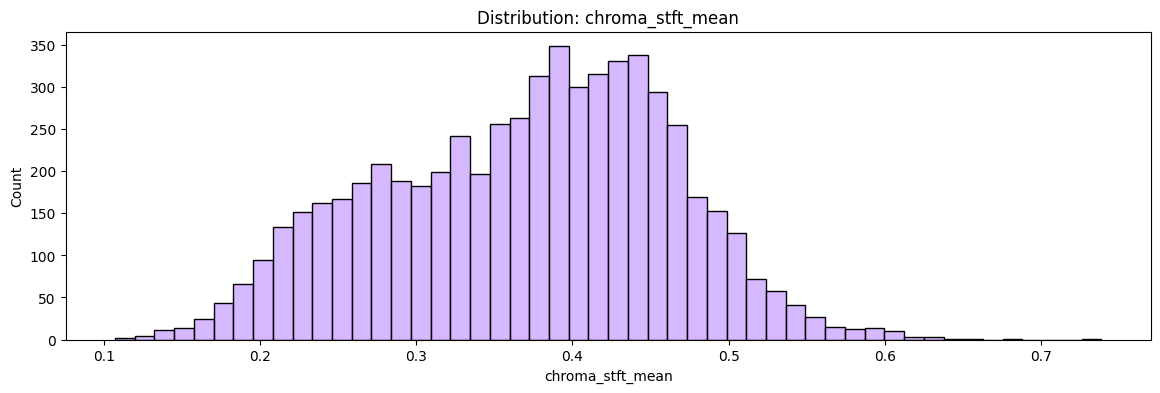

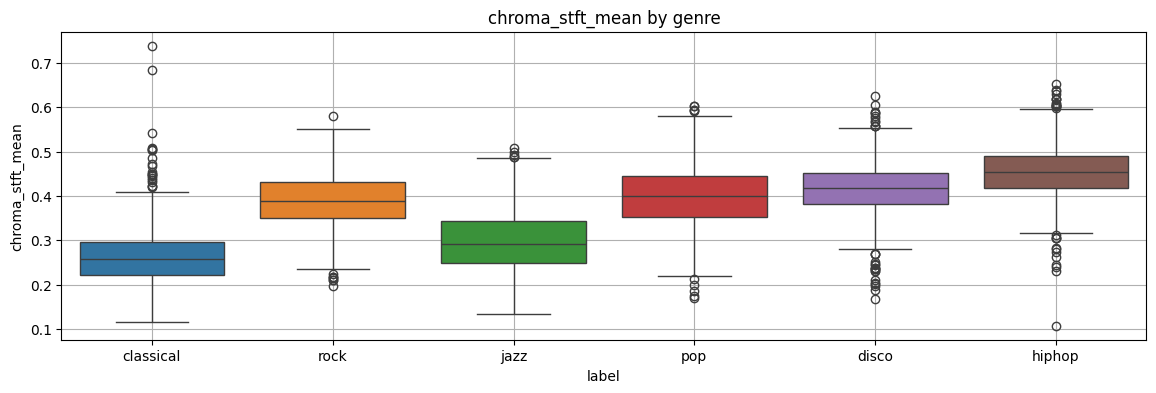

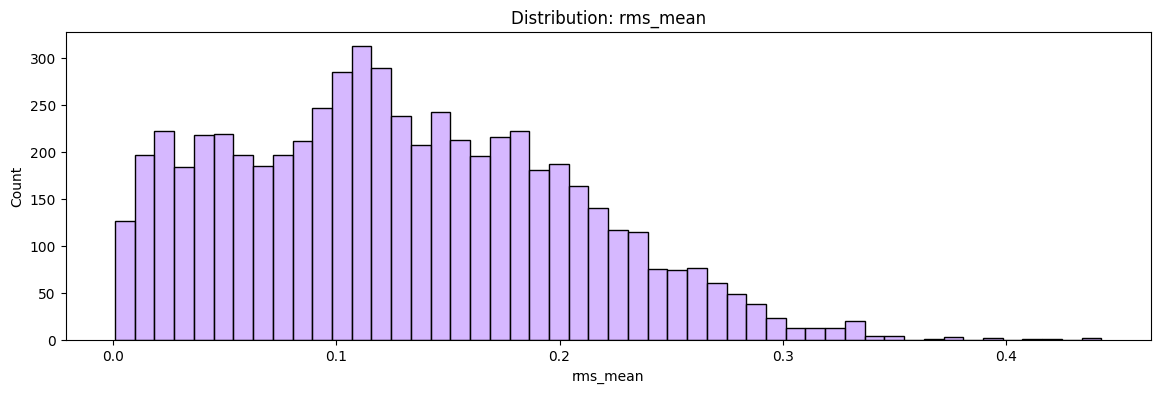

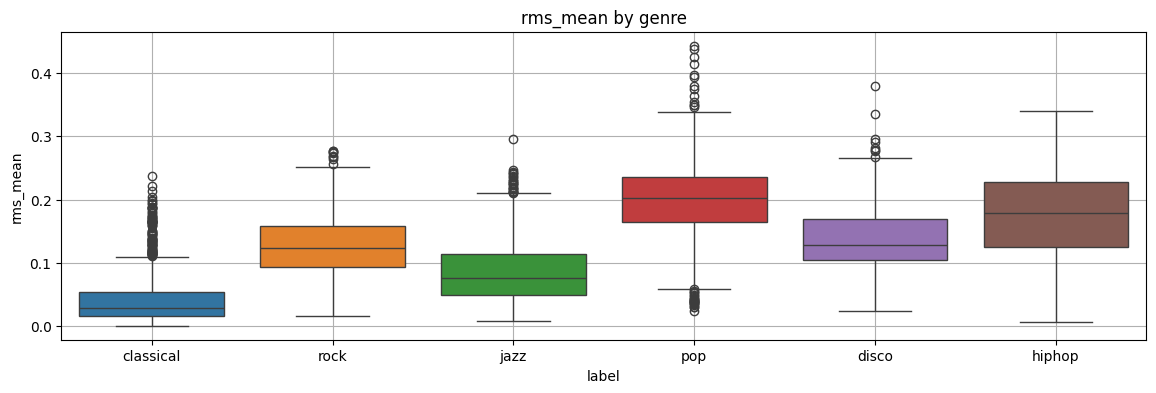

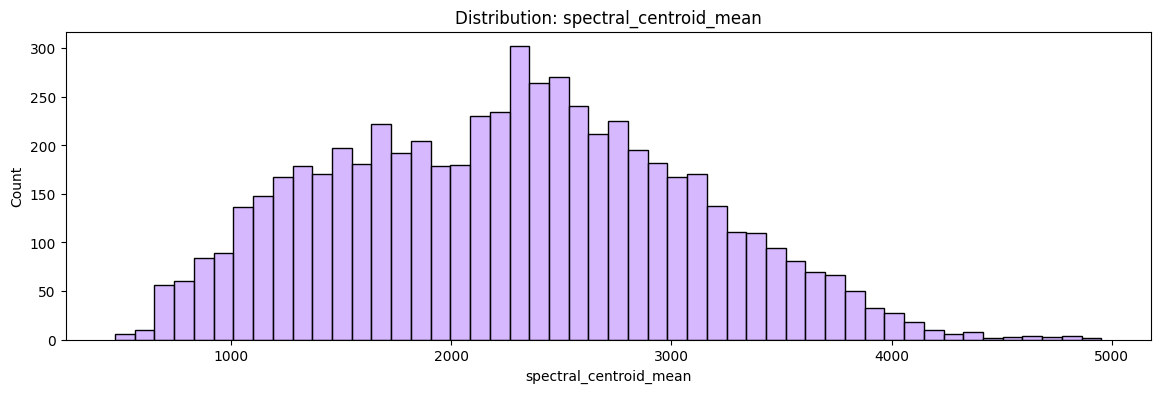

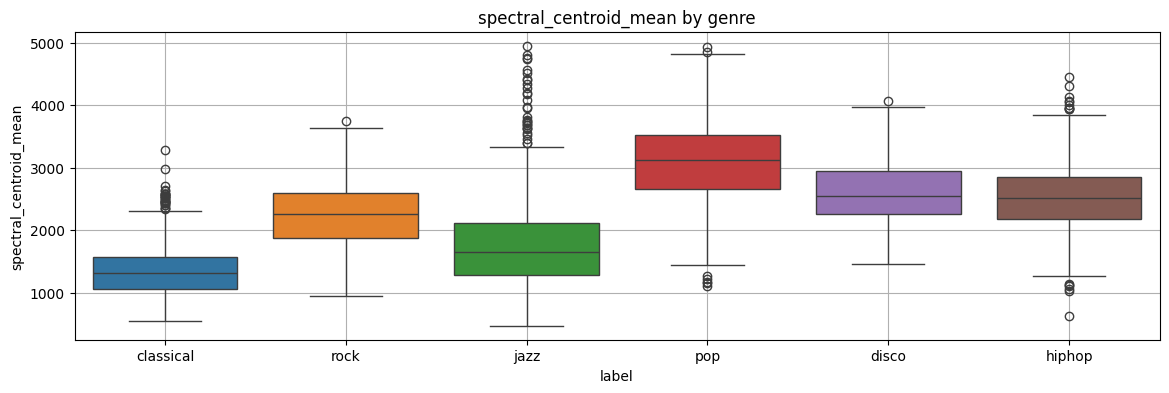

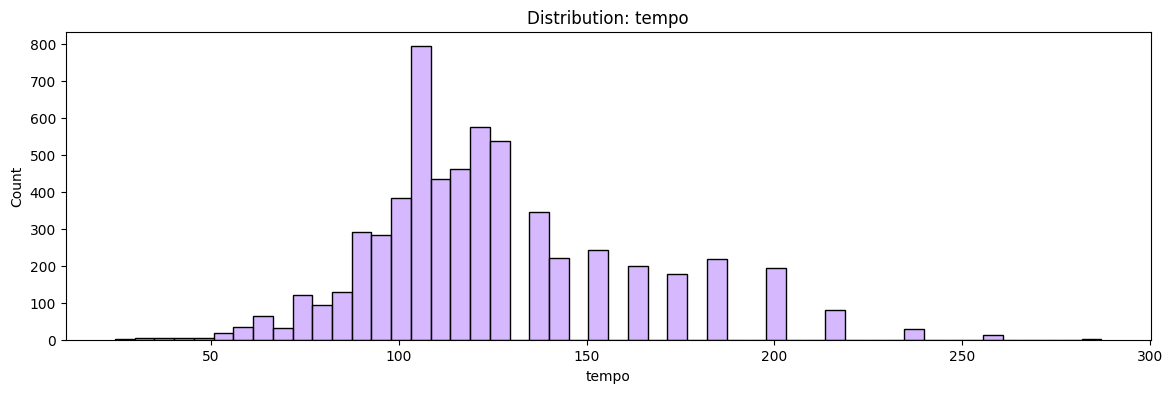

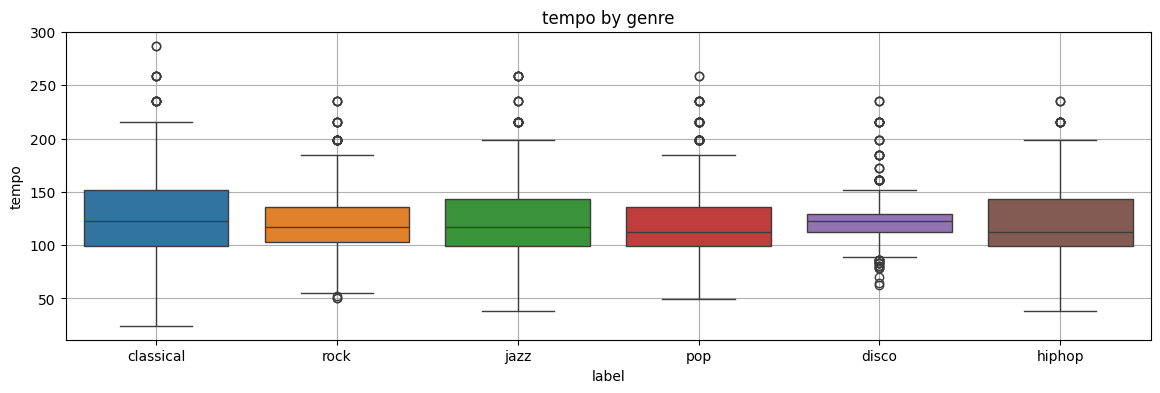

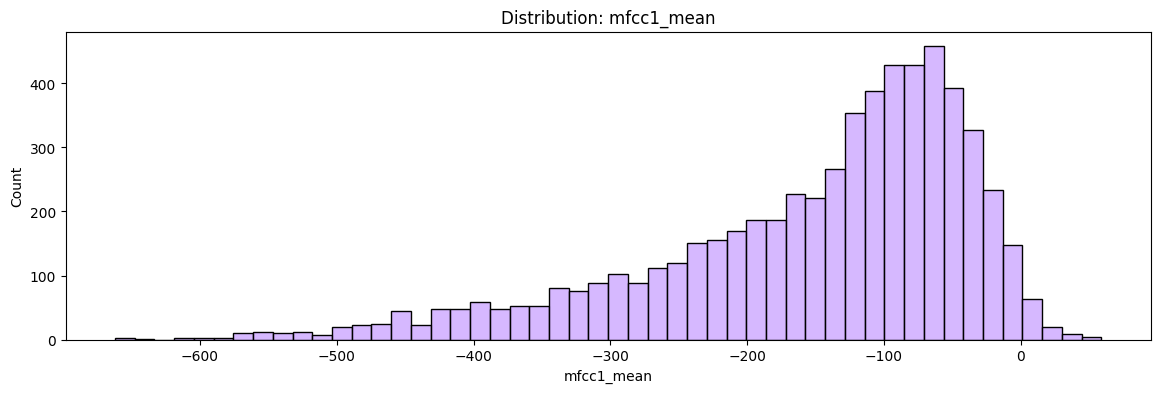

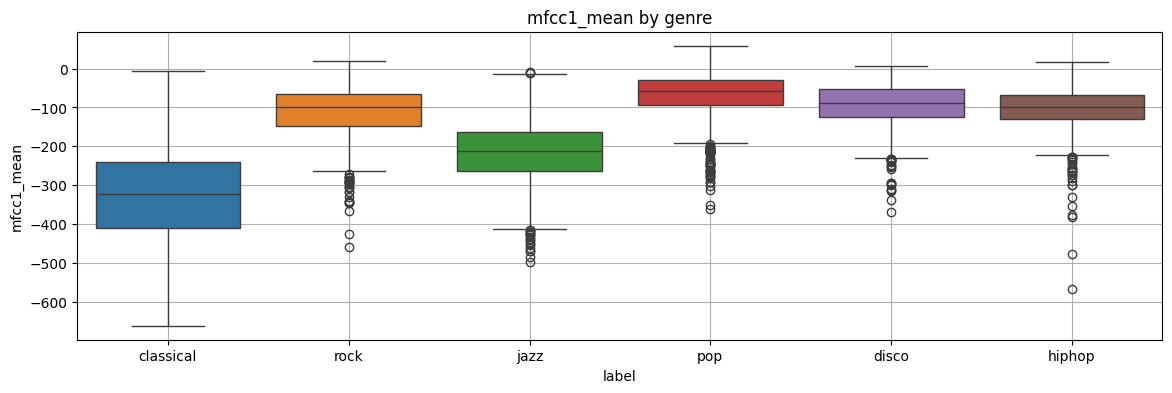

In [ ]:
#gurleen
#distribution analysis using histogram and box plot
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

numeric_cols = ["chroma_stft_mean","rms_mean","spectral_centroid_mean","tempo","mfcc1_mean"]
for col in numeric_cols:
    plt.figure(figsize=(14, 4))
    sns.histplot(data=df, x=col, bins=50, color="#C9A0FF")
    plt.title(f"Distribution: {col}")
    plt.show()
    plt.figure(figsize=(14, 4))
    sns.boxplot(data=df, y=col, x="label", hue="label")
    plt.title(f"{col} by genre")
    plt.grid()
    plt.show()


'Sub-sampling: A pairplot creates an NxN grid of scatter plots.Taking a random sample of 500 rows makes the plot render almost instantly while still showing clear distribution trends.\n   Random_state=42: Ensures reproducibility—you get the exact same random sample of songs every time you run the code.'

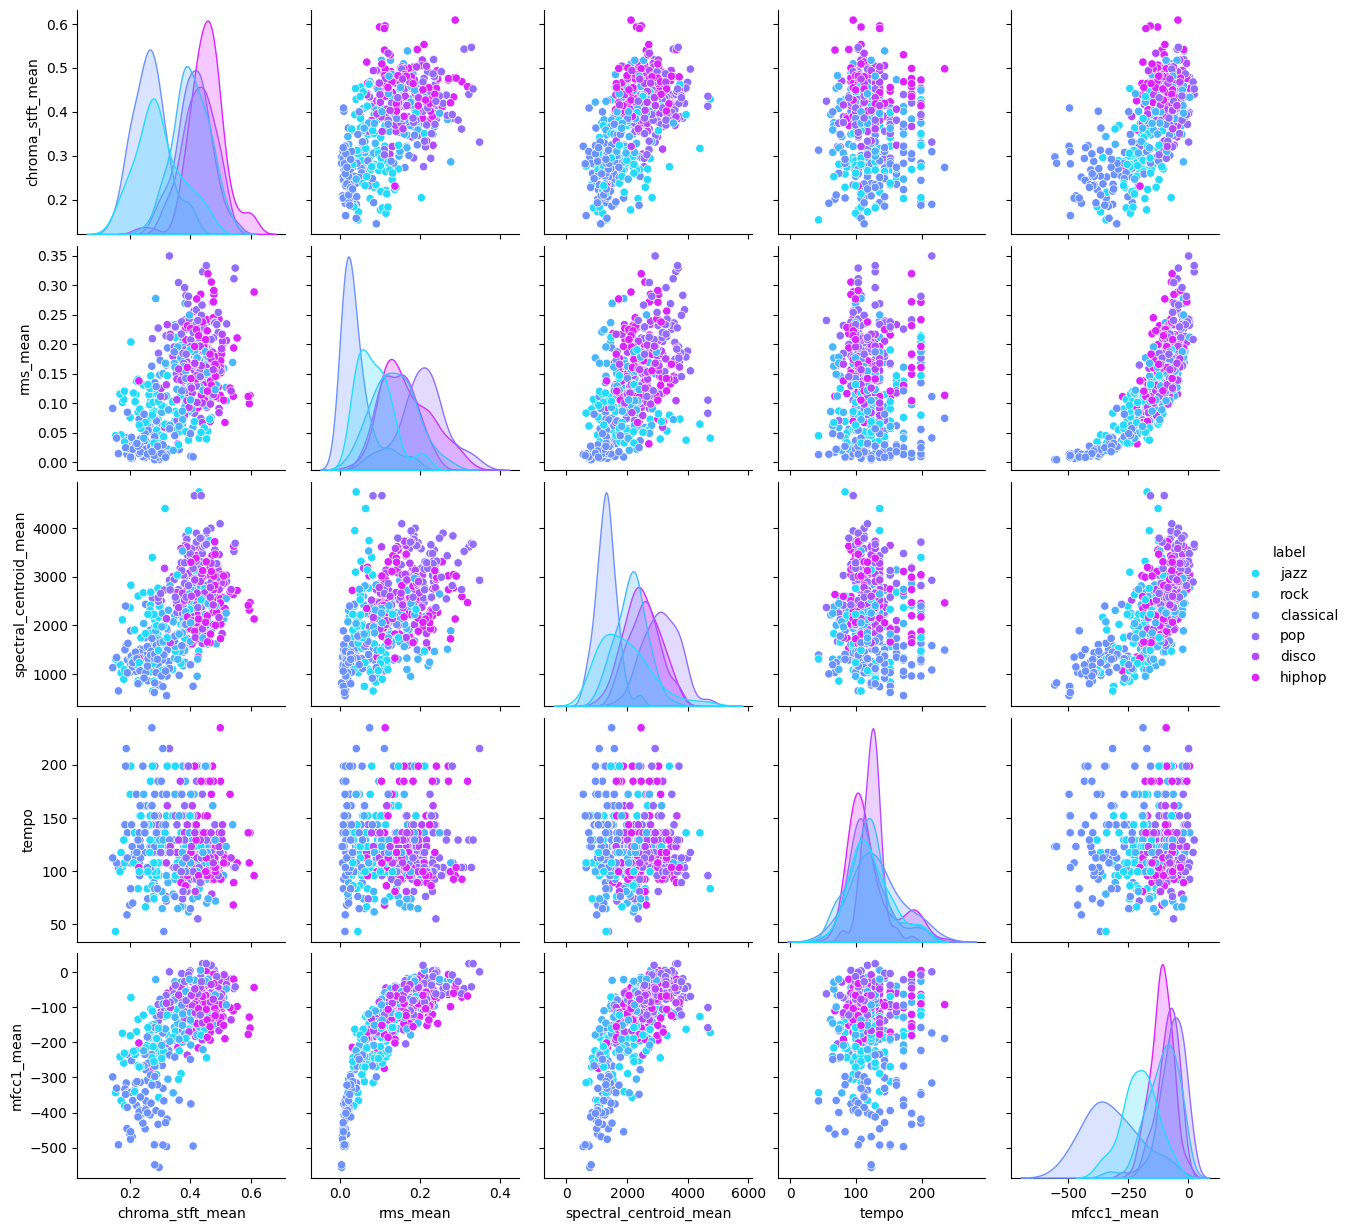

In [ ]:
#gurleen
#pairwise relationships
pair_cols = ["chroma_stft_mean","rms_mean","spectral_centroid_mean","tempo","mfcc1_mean","label"]
sns.pairplot(df[pair_cols].sample(min(500, len(df)), random_state=42), hue="label", palette="cool")
'''Sub-sampling: A pairplot creates an NxN grid of scatter plots.Taking a random sample of 500 rows makes the plot render almost instantly while still showing clear distribution trends.
   Random_state=42: Ensures reproducibility—you get the exact same random sample of songs every time you run the code.'''

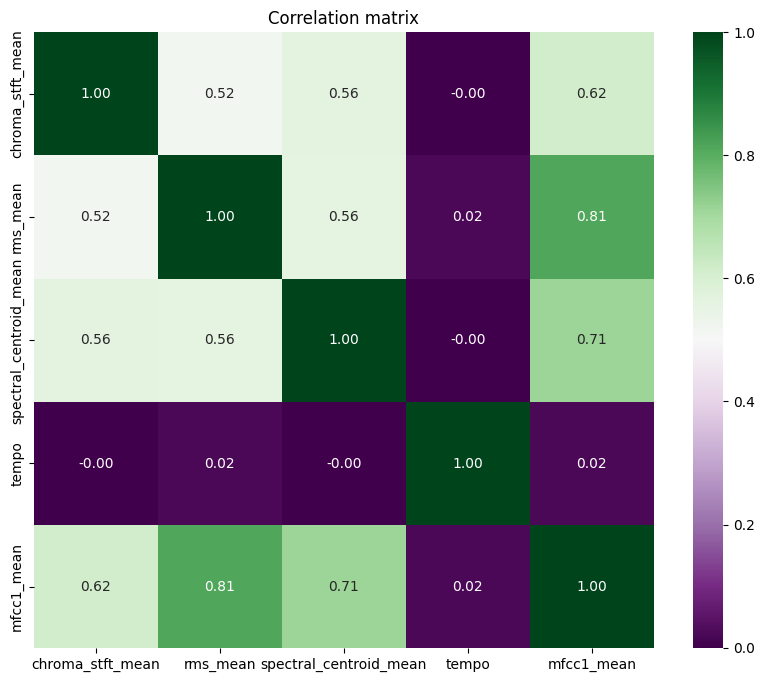

In [ ]:
#gurleen
corr_cols = ["chroma_stft_mean","rms_mean","spectral_centroid_mean","tempo","mfcc1_mean","label"]
corr_matrix = df[corr_cols].corr(numeric_only=True)

plt.figure(figsize=(10, 8))
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap='PRGn')
plt.title("Correlation matrix")
plt.show()



In [ ]:
#Snigdha
#using Librosa to extract features from .wav files.
#First, install Librosa alongside soundfile (for loading audio formats) and matplotlib (for optional visualization)

'''
When you load an audio file using librosa.load, it automatically resamples the audio to a default sampling rate of 22,050 Hz and normalizes the amplitude.
It returns a 1D NumPy array representing the audio time-series signal (y) and the sample rate (sr)
'''
import librosa
import numpy as np

# Load audio file (supports WAV, MP3, FLAC, etc.)
audio_path = "/content/classical.00000.wav"
y, sr = librosa.load(audio_path, sr=None)  # sr=None preserves native sample rate
# Extract 13 MFCCs (commonly 13 to 40 are used)
mfccs = librosa.feature.mfcc(y=y, sr=sr, n_mfcc=13)
print("MFCCs shape:", mfccs.shape)  # Shape: (n_mfcc, number_of_frames)
chromagram = librosa.feature.chroma_stft(y=y, sr=sr)
print("Chroma shape:", chromagram.shape)  # Shape: (12, number_of_frames)
rms = librosa.feature.rms(y=y)
print("RMS shape:", rms.shape)  # Shape: (1, number_of_frames)
spectral_centroids = librosa.feature.spectral_centroid(y=y, sr=sr)
'''
Because audio files have different lengths, the extracted feature matrices will have varying numbers of time frames.
 To pass these into standard tabular machine learning models (like Random Forests, SVMs, or XGBoost), you should compress the
 time axis by calculating the mean and standard deviation across all frames
'''
# Function to aggregate features into a single row vector
def extract_global_features(y, sr):
    features = {}

    # Calculate raw features
    mfcc_feat = librosa.feature.mfcc(y=y, sr=sr, n_mfcc=13)
    chroma_feat = librosa.feature.chroma_stft(y=y, sr=sr)
    rms_feat = librosa.feature.rms(y=y)

    # Aggregate over time windows using Mean and Std Dev
    features['mfcc_mean'] = np.mean(mfcc_feat, axis=1)
    features['mfcc_std'] = np.std(mfcc_feat, axis=1)

    features['chroma_mean'] = np.mean(chroma_feat, axis=1)
    features['rms_mean'] = np.mean(rms_feat)

    # Flatten everything into a single 1D array
    feature_vector = np.concatenate([
        features['mfcc_mean'],
        features['mfcc_std'],
        features['chroma_mean'],
        [features['rms_mean']]
    ])

    return feature_vector

# Extract a static feature row for one file
ML_ready_features = extract_global_features(y, sr)
print("Final feature vector size:", ML_ready_features.shape)

# 1. Load audio and extract spectral features
y, sr = librosa.load('/content/classical.00000.wav', sr=None)

spectral_centroids = librosa.feature.spectral_centroid(y=y, sr=sr)
# 2. Calculate the mean across time frames (axis=1)
# This squeezes the 2D array into a single average scalar value
mean_centroid = np.mean(spectral_centroids, axis=1)[0]


print(f"Mean Spectral Centroid: {mean_centroid:.2f} Hz")

MFCCs shape: (13, 1293)
Chroma shape: (12, 1293)
RMS shape: (1, 1293)
Final feature vector size: (39,)
Mean Spectral Centroid: 1505.36 Hz


In [10]:
#Snigdha
#Extracting all imp audio features
import librosa
import numpy as np

# 1. Load the audio file
y, sr = librosa.load('/content/classical.00000.wav', sr=None)

# 2. Extract Features
spectral_centroids = librosa.feature.spectral_centroid(y=y, sr=sr)
# 2. Calculate the mean across time frames (axis=1)
# This squeezes the 2D array into a single average scalar value
mean_centroid = np.mean(spectral_centroids, axis=1)[0]


print(f"Mean Spectral Centroid: {mean_centroid:.2f} Hz")

# Tempo (returns a scalar or a 1D array depending on your librosa version)
tempo, _ = librosa.beat.beat_track(y=y, sr=sr)

# MFCCs (returns 2D array: [n_mfcc, time_frames])
mfccs = librosa.feature.mfcc(y=y, sr=sr, n_mfcc=13)

# Chroma (returns 2D array: [12_pitch_classes, time_frames])
chroma = librosa.feature.chroma_stft(y=y, sr=sr)

# Spectral Centroid (returns 2D array: [1, time_frames])
spectral_centroids = librosa.feature.spectral_centroid(y=y, sr=sr)

# Energy / RMS (returns 2D array: [1, time_frames])
energy = librosa.feature.rms(y=y)

# 3. Calculate Means (Averaging over time)

# Tempo is already an overall average metric, no axis needed
mean_tempo = tempo[0] if isinstance(tempo, np.ndarray) else tempo

# 2D features require axis=1 to average across the time columns
mean_mfccs = np.mean(mfccs, axis=1)              # Returns 13 values (one per coefficient)
mean_chroma = np.mean(chroma, axis=1)            # Returns 12 values (one per pitch)
mean_centroid = np.mean(spectral_centroids, axis=1)[0] # Returns a single scalar
mean_energy = np.mean(energy, axis=1)[0]         # Returns a single scalar


# 4. Print Results

print(f"Tempo: {mean_tempo:.2f} BPM")
print(f"Mean Centroid: {mean_centroid:.2f} Hz")
print(f"Mean Energy (RMS): {mean_energy:.4f}")
print(f"Mean MFCCs (first 3): {mean_mfccs[:3]}")
print(f"Mean Chroma (first 3): {mean_chroma[:3]}")


Mean Spectral Centroid: 1505.36 Hz
Tempo: 95.70 BPM
Mean Centroid: 1505.36 Hz
Mean Energy (RMS): 0.0362
Mean MFCCs (first 3): [-268.21857   135.68166   -34.056377]
Mean Chroma (first 3): [0.1244859  0.29797456 0.4111422 ]


In [11]:
#gurleen
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression


from sklearn.metrics import accuracy_score, classification_report, f1_score
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.svm import SVC

In [13]:
#gurleen
target_col = 'label'
ignore_cols = [target_col, 'filename', 'length']

# Automatically select ALL numerical feature columns
feature_cols = [c for c in df.columns if c not in ignore_cols]

X = df[feature_cols]
y = df[target_col]


X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, stratify=y, random_state=42)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

models = {
    'KNN': KNeighborsClassifier(n_neighbors=5),
    'SVM': SVC(kernel='rbf', class_weight='balanced', random_state=42),
    'Random Forest': RandomForestClassifier(
        n_estimators=200, class_weight='balanced', random_state=42
    ),
    'Logistic Regression': LogisticRegression(
        max_iter=1000, class_weight='balanced', random_state=42
    ),
}


results = {}

print("   MODEL EVALUATION   ")
for name, model in models.items():
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)

    acc = accuracy_score(y_test, y_pred)
    results[name] = acc
    print(f"{name} Accuracy: {acc:.4f}")
'''for name, model in models.items():
  # Train model
  model.fit(X_train_scaled, y_train)

  # Predict
  y_pred = model.predict(X_test_scaled)

  # Evaluate
  acc = accuracy_score(y_test, y_pred)
  macro_f1 = f1_score(y_test, y_pred, average='macro')
  results[name] = macro_f1

  print(f"\n{name}:")
  print(f"  Accuracy: {acc:.4f}")
  print(f"  Macro F1: {macro_f1:.4f}")

plt.figure(figsize=(8, 4))
sns.barplot(x=list(results.keys()), y=list(results.values()), palette='viridis')
plt.title('Model Performance Comparison (Macro F1-Score)')
plt.ylabel('Macro F1-Score')
plt.ylim(0, 1.0)
plt.show()'''



   MODEL EVALUATION   


ValueError: Input X contains NaN.
KNeighborsClassifier does not accept missing values encoded as NaN natively. For supervised learning, you might want to consider sklearn.ensemble.HistGradientBoostingClassifier and Regressor which accept missing values encoded as NaNs natively. Alternatively, it is possible to preprocess the data, for instance by using an imputer transformer in a pipeline or drop samples with missing values. See https://scikit-learn.org/stable/modules/impute.html You can find a list of all estimators that handle NaN values at the following page: https://scikit-learn.org/stable/modules/impute.html#estimators-that-handle-nan-values

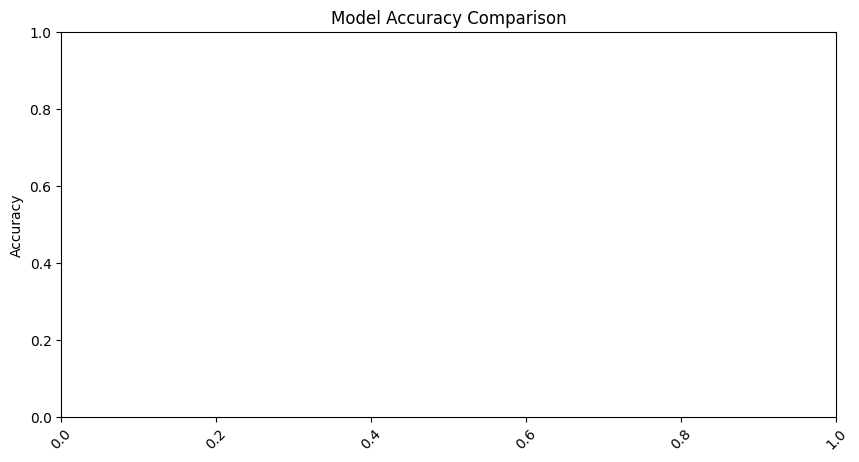

In [7]:
# gurleen
#Model Accuracy Comparision Bar Chart
sorted_results = dict(sorted(results.items(), key=lambda item: item[1], reverse=True))
plt.figure(figsize=(10,5))
sns.barplot(x=list(sorted_results.keys()), y=list(sorted_results.values()))
plt.title("Model Accuracy Comparison")
plt.ylabel("Accuracy")
plt.xticks(rotation=45)
plt.show()

In [14]:
#gurleen
'''from sklearn.preprocessing import StandardScaler, LabelEncoder
le_artist = LabelEncoder()
le_track = LabelEncoder()
train_encoded = df_train.copy()
encoded_feature_names = list(train_encoded.columns)
encoded_feature_names.remove('Class
scaler = StandardScaler()
num_cols = ['Popularity', 'Danceability', 'Energy', 'Key', 'Loudness', 'Mode',
            'Speechiness','Acousticness', 'Instrumentalness', 'Liveness', 'Valence',
            'Tempo', 'Duration_in_min/ms', 'Time_Signature']
train_encoded[num_cols] = scaler.fit_transform(train_encoded[num_cols])
df_train = train_encoded.copy()
# Encoding df_test
test_encoded = df_test.copy()


from sklearn.svm import SVC
from sklearn.naive_bayes import GaussianNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, AdaBoostClassifier, GradientBoostingClassifier

import lightgbm as lgb
import xgboost as xgb

from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV
from sklearn.metrics import accuracy_score, classification_report, confusion_matri
X = df_train.drop(columns=['Class'])
y = df_train['Class']
# Train-test split (stratified to handle imbalance)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, stratify=y)
models = {
    "SVM": SVC(gamma='scale', class_weight='balanced'),
    "Naive Bayes": GaussianNB(),
    "Decision Tree": DecisionTreeClassifier(class_weight='balanced'),
    "Random Forest": RandomForestClassifier(class_weight='balanced'),
    "AdaBoost": AdaBoostClassifier(),
    "Gradient Boosting": GradientBoostingClassifier(),
    "LightGBM": lgb.LGBMClassifier(class_weight='balanced', verbosity=-1)
}

results = {}

for name, model in models.items():
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)

    acc = accuracy_score(y_test, y_pred)
    results[name] = acc
    print(f"{name} Accuracy: {acc:.4f}"

    # Model Accuracy Comparision Bar Chart
sorted_results = dict(sorted(results.items(), key=lambda item: item[1], reverse=True))
plt.figure(figsize=(10,5))
sns.barplot(x=list(sorted_results.keys()), y=list(sorted_results.values()))
plt.title("Model Accuracy Comparison")
plt.ylabel("Accuracy")
plt.xticks(rotation=45)
plt.show()'''


'from sklearn.preprocessing import StandardScaler, LabelEncoder\nle_artist = LabelEncoder()\nle_track = LabelEncoder()\ntrain_encoded = df_train.copy()\nencoded_feature_names = list(train_encoded.columns)\nencoded_feature_names.remove(\'Class\nscaler = StandardScaler()\nnum_cols = [\'Popularity\', \'Danceability\', \'Energy\', \'Key\', \'Loudness\', \'Mode\',\n            \'Speechiness\',\'Acousticness\', \'Instrumentalness\', \'Liveness\', \'Valence\',\n            \'Tempo\', \'Duration_in_min/ms\', \'Time_Signature\']\ntrain_encoded[num_cols] = scaler.fit_transform(train_encoded[num_cols])\ndf_train = train_encoded.copy()\n# Encoding df_test\ntest_encoded = df_test.copy()\n\n\nfrom sklearn.svm import SVC\nfrom sklearn.naive_bayes import GaussianNB\nfrom sklearn.tree import DecisionTreeClassifier\nfrom sklearn.ensemble import RandomForestClassifier, AdaBoostClassifier, GradientBoostingClassifier\n\nimport lightgbm as lgb\nimport xgboost as xgb\n\nfrom sklearn.model_selection import tr

In [15]:
#gurleen
'''import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)
import matplotlib.pyplot as plt
import seaborn as sns

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

import warnings
warnings.filterwarnings("ignore")
df_train = pd.read_csv("/kaggle/input/music-genre-classification/train.csv")
df_test = pd.read_csv("/kaggle/input/music-genre-classification/test.csv")
df_train = pd.read_csv('train.csv')
df_test = pd.read_csv('test.csv')

# 2. Inspect shape and missing values
print("Train dataset shape:", df_train.shape)
print("Test dataset shape:", df_test.shape)
print("\nMissing values in Train:\n", df_train.isnull().sum())

# 3. Check class balance across genres
print("\n=== CLASS BALANCE ACROSS GENRES ===")
print(df_train['Class'].value_counts())

# 4. Plot class distribution
plt.figure(figsize=(8, 4))
sns.countplot(data=df_train, x='Class', palette='viridis')
plt.title('Genre Class Distribution')
plt.xlabel('Genre Class ID')
plt.ylabel('Number of Tracks')
plt.show()'''

'import pandas as pd\nimport numpy as np\nimport matplotlib.pyplot as plt\nimport seaborn as sns\nimport numpy as np # linear algebra\nimport pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)\nimport matplotlib.pyplot as plt\nimport seaborn as sns\n\nimport os\nfor dirname, _, filenames in os.walk(\'/kaggle/input\'):\n    for filename in filenames:\n        print(os.path.join(dirname, filename))\n\nimport warnings\nwarnings.filterwarnings("ignore")\ndf_train = pd.read_csv("/kaggle/input/music-genre-classification/train.csv")\ndf_test = pd.read_csv("/kaggle/input/music-genre-classification/test.csv")\ndf_train = pd.read_csv(\'train.csv\')\ndf_test = pd.read_csv(\'test.csv\')\n\n# 2. Inspect shape and missing values\nprint("Train dataset shape:", df_train.shape)\nprint("Test dataset shape:", df_test.shape)\nprint("\nMissing values in Train:\n", df_train.isnull().sum())\n\n# 3. Check class balance across genres\nprint("\n=== CLASS BALANCE ACROSS GENRES ===")\nprint(df_train[

In [ ]:
#Snigdha
#work to be done now
'''
KNN (K-Nearest Neighbors): Looks at a new data point and finds the closest matching data points in your existing dataset, assigning it the most common category among
those neighbors.
SVM (Support Vector Machine): Draws an optimal dividing line (or boundary) through your data space to separate different categories from each other as cleanly as possible.
Random Forest: Builds multiple decision trees using random parts of your data and combines their individual votes to make a final, highly accurate classification.
Logistic Regression: Calculates the mathematical probability that a data point belongs to a particular class (using a score from 0 to 1) to make a binary decision.
Feature Scaling: Adjusts and standardizes the numeric ranges of your data columns so that variables with large numbers don't unfairly overpower smaller numbers during
calculations.
CNN on Spectrogram Images: Takes sound or time-series signal data, converts it into a visual frequency graph (spectrogram), and scans that image to recognize patterns.
'''
